In [11]:
# Experiment 2: Exploratory Data Analysis (EDA)
# Dataset: Titanic train.csv

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [13]:
#Step 2: Load the Titanic dataset
# Load dataset
df = pd.read_csv("train.csv")

# Display first five records
print(df.head())

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  


In [14]:
#Step 3: Check dataset information
# Dataset shape
print("Dataset Shape:", df.shape)

# Dataset information
df.info()

# Column names
print("Columns:", df.columns.tolist())

Dataset Shape: (891, 12)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB
Columns: ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


In [15]:
#Step 4: Generate statistical summary
# Statistical summary of numerical columns
print(df.describe())

# Statistical summary of categorical columns
print(df.describe(include='object'))

# Calculate mean, median and mode of Age
print("Mean Age:", df['Age'].mean())
print("Median Age:", df['Age'].median())
print("Mode Age:", df['Age'].mode()[0])

       PassengerId    Survived      Pclass         Age       SibSp  \
count   891.000000  891.000000  891.000000  714.000000  891.000000   
mean    446.000000    0.383838    2.308642   29.699118    0.523008   
std     257.353842    0.486592    0.836071   14.526497    1.102743   
min       1.000000    0.000000    1.000000    0.420000    0.000000   
25%     223.500000    0.000000    2.000000   20.125000    0.000000   
50%     446.000000    0.000000    3.000000   28.000000    0.000000   
75%     668.500000    1.000000    3.000000   38.000000    1.000000   
max     891.000000    1.000000    3.000000   80.000000    8.000000   

            Parch        Fare  
count  891.000000  891.000000  
mean     0.381594   32.204208  
std      0.806057   49.693429  
min      0.000000    0.000000  
25%      0.000000    7.910400  
50%      0.000000   14.454200  
75%      0.000000   31.000000  
max      6.000000  512.329200  
                           Name   Sex  Ticket Cabin Embarked
count               

C:\Users\HEMENT\AppData\Local\Temp\ipykernel_13656\1503030064.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(df.describe(include='object'))


In [16]:
#Step 5: Check missing and duplicate values
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("Duplicate Records:", df.duplicated().sum())

Missing Values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64
Duplicate Records: 0


Survived
0    549
1    342
Name: count, dtype: int64


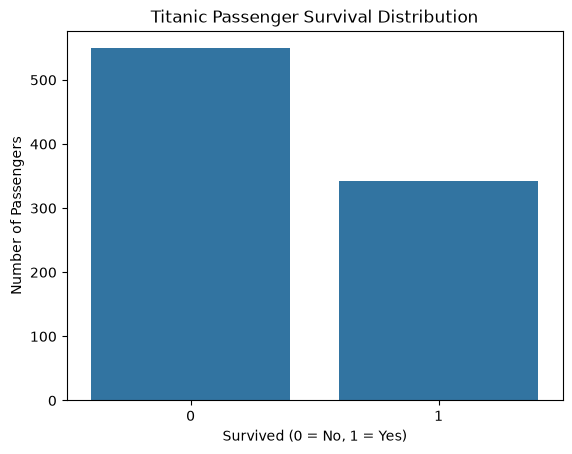

In [17]:
#Step 6: Analyze survival distribution
# Count survived and non-survived passengers
print(df['Survived'].value_counts())

# Plot survival distribution
sns.countplot(data=df, x='Survived')

plt.title("Titanic Passenger Survival Distribution")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")
plt.show()

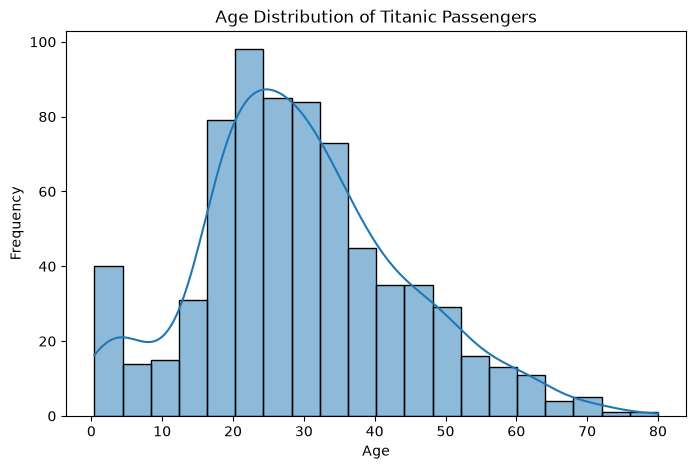

In [18]:
#Step 7: Analyze passenger age distribution
plt.figure(figsize=(8, 5))

sns.histplot(df['Age'].dropna(), bins=20, kde=True)

plt.title("Age Distribution of Titanic Passengers")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

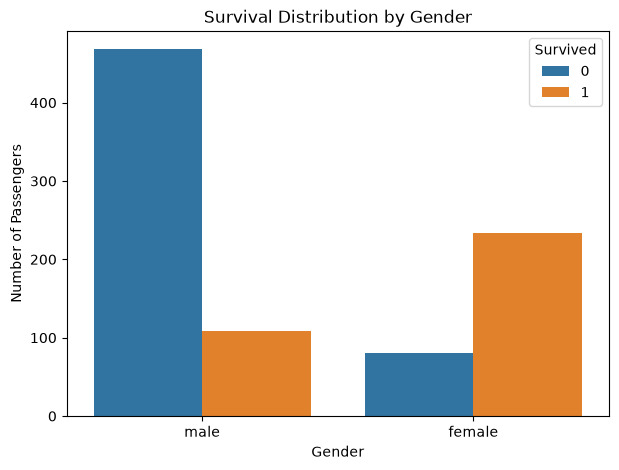

In [19]:
#Step 8: Analyze survival based on gender
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='Sex', hue='Survived')

plt.title("Survival Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")

plt.show()

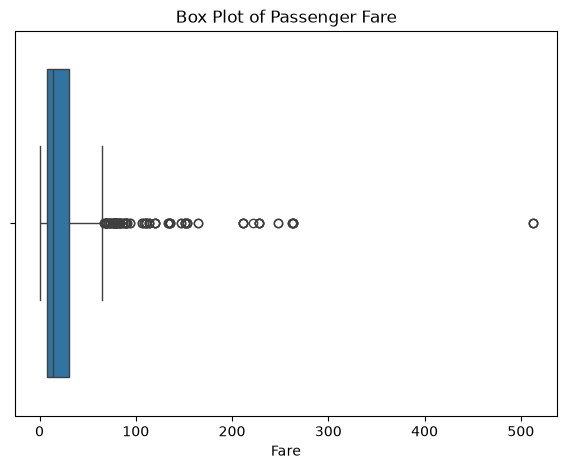

In [20]:
#Step 9: Identify outliers using Box Plot
plt.figure(figsize=(7, 5))

sns.boxplot(x=df['Fare'])

plt.title("Box Plot of Passenger Fare")
plt.xlabel("Fare")

plt.show()

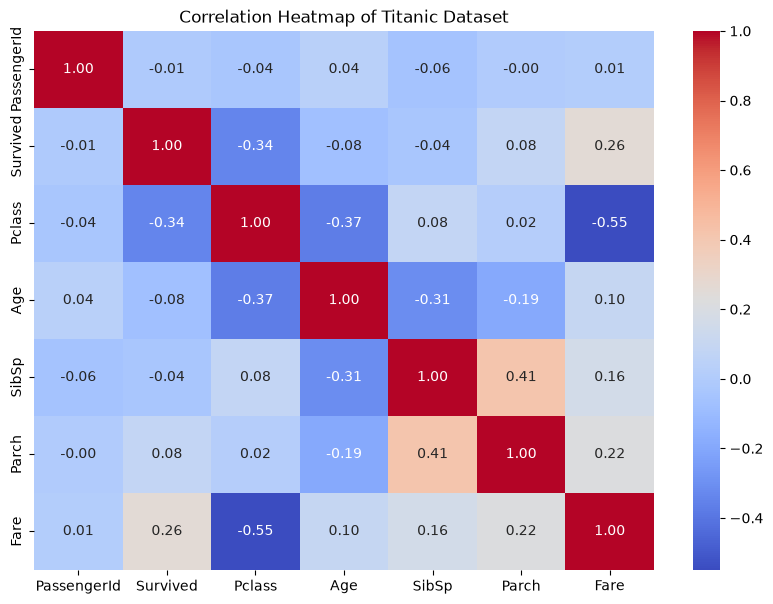

In [21]:
#Step 10: Analyze correlation using Heatmap
# Select numerical columns
numeric_df = df.select_dtypes(include=np.number)

# Calculate correlation
correlation = numeric_df.corr()

# Display heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap of Titanic Dataset")
plt.show()

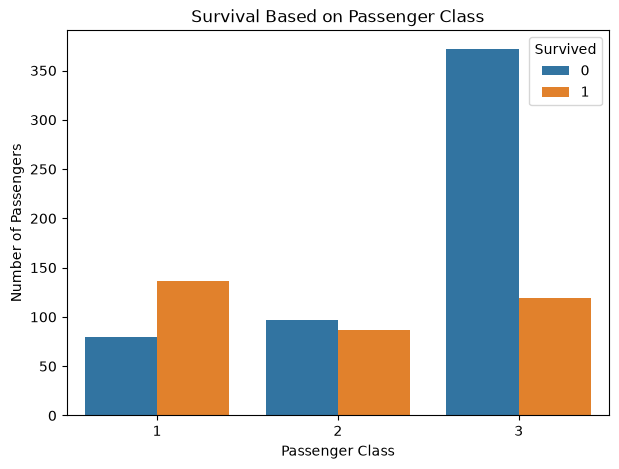

In [22]:
#Step 11: Analyze passenger class and survival
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='Pclass', hue='Survived')

plt.title("Survival Based on Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")

plt.show()